# 03 · H2: проверка механизмов генерации риска

**Задача:** до ML-эксперимента проверить математические сценарии S0–S3 и сохранение распределения признаков $P(X)$. Это **диагностический ноутбук**, а не проверка преимущества алгоритмов.

- **S0** — опубликованная PLCOm2012.
- **S1** — замена компонентов стажа и интенсивности совместной мужской моделью Remen et al. (2018), Table 4 model 5.
- **S2** — замена стажа, интенсивности и времени после отказа на CSI с мужским коэффициентом Remen et al. (2018), Table 4 model 4.
- **S3** — специально сконструированные взаимодействия, научно мотивированные SYNERGY, но **не** опубликованные численные эффекты.

**Важно:** S1 и S2 — гибридные синтетические механизмы, не валидация опубликованных моделей в новой популяции. Дополнительные риски и промежуточные столбцы не являются входными признаками ML. Источники и точные заимствования — в `references/literature.md`.

## 1. Импорты и конфигурация

In [3]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

PROJECT_ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
                     if (p / 'src' / 'data_generation.py').is_file()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError('Запускайте Jupyter из корня репозитория или notebooks/')
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.data_generation import generate_baseline
from src.h2_generation import SCENARIOS, apply_h2_scenario, csi_index
from src.preprocessing import FEATURE_COLUMNS

print('Проект:', PROJECT_ROOT)
print('Python:', sys.version.split()[0])

Проект: /Users/dyadyundanil/Documents/lung-cancer-ml-study
Python: 3.11.11


In [5]:
N = 50_000
DATA_SEED = 42
OUTCOME_SEED = 2026
baseline = generate_baseline(n=N, seed=DATA_SEED)
scenarios = {
    name: apply_h2_scenario(baseline, scenario=name, outcome_seed=OUTCOME_SEED)
    for name in SCENARIOS
}
print('Пациентов в каждом сценарии:', N)

Пациентов в каждом сценарии: 50000


## 2. Сравним генерации

Проверяем одинаковые $X$, средний риск, наблюдаемую долю исходов и добавленную поправку к логиту. Средняя **истинная** вероятность специально калибруется на значение S0, но наблюдаемая доля `y=1` не обязана точно совпадать.

In [8]:
rows = []
for name, df in scenarios.items():
    rows.append({
        'Сценарий': name,
        'N': len(df),
        'Средний риск, %': 100 * df.risk.mean(),
        'Положительных': int(df.y.sum()),
        'Частота y=1, %': 100 * df.y.mean(),
        'Средняя |Δ logit|': float(df.delta_logit.abs().mean()),
        'Калибровка α': float(df.calibration_shift.iloc[0]),
        'p99 риска, %': 100 * df.risk.quantile(.99),
    })
summary = pd.DataFrame(rows).set_index('Сценарий')
display(summary.round(4))
for df in scenarios.values():
    pd.testing.assert_frame_equal(df[list(FEATURE_COLUMNS)], baseline[list(FEATURE_COLUMNS)])
    assert df.risk.between(0, 1, inclusive='neither').all()
    assert df.y.isin([0,1]).all()
assert np.allclose([d.risk.mean() for d in scenarios.values()], scenarios['S0'].risk.mean())
print('Проверки P(X) и калибровки пройдены.')

,N,"Средний риск, %",Положительных,"Частота y=1, %",Средняя |Δ logit|,Калибровка α,"p99 риска, %"
Сценарий,,,,,,,
S0,50000,0.8238,418,0.836,0.0000,0.0000,7.0331
S1,50000,0.8238,397,0.794,8.1948,-4.7315,6.1756
S2,50000,0.8238,406,0.812,6.0734,-2.3548,5.0686
S3,50000,0.8238,410,0.820,0.1112,0.0315,6.6383


Проверки P(X) и калибровки пройдены.


## 3. Распределение истинных вероятностей

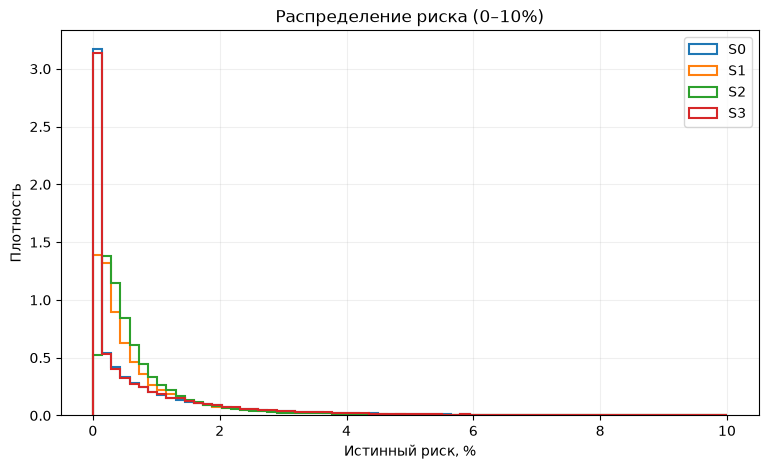

In [11]:
fig, ax = plt.subplots(figsize=(9, 5))
for name, df in scenarios.items():
    ax.hist(100 * df.risk, bins=np.linspace(0, 10, 70), density=True,
            histtype='step', linewidth=1.5, label=name)
ax.set(xlabel='Истинный риск, %', ylabel='Плотность', title='Распределение риска (0–10%)')
ax.legend(); ax.grid(alpha=.2)
plt.show()

**Вывод.** Несмотря на одинаковый средний риск, распределения индивидуальных вероятностей заметно различаются. Сценарии S0 и S3 демонстрируют выраженную концентрацию пациентов в области очень низкого риска, тогда как S1 и S2 перераспределяют часть наблюдений в область более высоких вероятностей. При этом верхние хвосты распределений S1 и S2 короче, чем у S0.

Таким образом, изменение математического механизма генерации влияет на структуру риска даже при сохранении его среднего значения.

## 4. Как меняется механизм риска при одинаковых пациентах?

Группируем пациентов по стажу курения и интенсивности; сравниваем **средний риск**, но не трактуем графики как причинные эффекты (остальные признаки по группам тоже могут различаться).

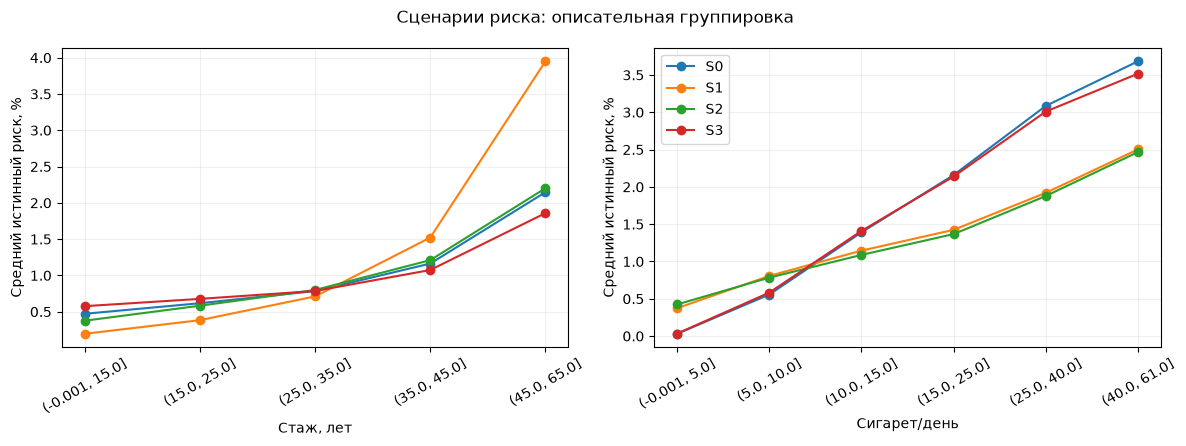

In [14]:
df0 = scenarios['S0']
fig, axs = plt.subplots(1, 2, figsize=(12, 4.5))
for name, df in scenarios.items():
    for ax, col, bins, label in [
        (axs[0], 'smoking_years', [0, 15, 25, 35, 45, 65], 'Стаж, лет'),
        (axs[1], 'cigs_per_day', [0, 5, 10, 15, 25, 40, 61], 'Сигарет/день'),
    ]:
        grouped = df.groupby(pd.cut(df[col], bins=bins, include_lowest=True),
                             observed=True)['risk'].mean()
        ax.plot(np.arange(len(grouped)), grouped.to_numpy() * 100, marker='o', label=name)
        ax.set_xticks(np.arange(len(grouped)), [str(x) for x in grouped.index], rotation=30)
        ax.set(xlabel=label, ylabel='Средний истинный риск, %')
        ax.grid(alpha=.2)
axs[1].legend()
fig.suptitle('Сценарии риска: описательная группировка')
plt.tight_layout(); plt.show()

**Вывод.** Во всех сценариях прослеживается увеличение среднего риска с ростом продолжительности и интенсивности курения, однако характер зависимостей различается.

В S1 наблюдается наиболее выраженный рост риска при большом стаже курения, тогда как S2 показывает более умеренное изменение. По интенсивности курения сценарии S0 и S3 практически совпадают, а S1 и S2 демонстрируют более сглаженную зависимость и меньшие средние риски в группах наиболее интенсивного курения.

## 5. Проверяем заданные функции на примере

Для CSI используем опубликованные **26 лет** (период полураспада) и **лаг 1 год**, а S3 реализует **наши** две нелинейные поправки на логит. И CSI, и новые взаимодействия рассчитаны из тех же наблюдаемых признаков, но **их значения не передаём в модели**.

In [17]:
sample = baseline.iloc[:8].copy()
explain = sample[['smoking_years', 'cigs_per_day', 'quit_years', 'is_current_smoker']].copy()
explain['CSI'] = csi_index(sample.smoking_years, sample.cigs_per_day, sample.quit_years)
for scenario in ('S1','S2','S3'):
    explain[f'Δ logit {scenario}'] = scenarios[scenario]['delta_logit'].iloc[:8].to_numpy()
display(explain.round(3))

,smoking_years,cigs_per_day,quit_years,is_current_smoker,CSI,Δ logit S1,Δ logit S2,Δ logit S3
0,28,10,0,1,1.230,4.548,2.361,0.000
1,21,32,0,1,1.445,3.757,1.611,0.119
2,25,2,0,1,0.519,10.687,8.815,-0.047
3,15,8,3,0,0.687,4.337,2.610,-0.064
4,22,3,11,0,0.471,7.788,6.149,-0.076
5,18,8,13,0,0.608,4.458,2.720,-0.023
6,14,25,7,0,0.865,3.477,1.449,0.240
7,35,8,0,1,1.310,5.142,2.698,0.029


**Вывод.** На примерах отдельных пациентов видно, что комплексный индекс курения CSI и изменения логита зависят от индивидуальной комбинации характеристик курения. Сценарии S1 и S2 вызывают значительно более выраженные изменения относительно PLCOm2012, тогда как добавленные взаимодействия в S3 приводят к сравнительно небольшим положительным или отрицательным поправкам.

Это подтверждает, что новые сценарии формируют различные механизмы риска. Однако величина изменений существенно различается, поэтому при оценке H2 необходимо разграничивать влияние сложности зависимостей и силы внесённых модификаций.

## 6. Предварительное заключение

После выполнения ячеек сформулируем вывод только о **корректности и различии генеративных механизмов**: распределения X одинаковы, средняя истинная частота сопоставима, а формы индивидуальных рисков различаются. Лишь следующий ноутбук проверит, какие ML-модели лучше восстанавливают эти различия. Никакие коэффициенты сценариев нельзя подбирать по результатам тестирования моделей.

**Ограничение сценариев**. S1 и S2 изменяют исходную модель PLCOm2012 существенно сильнее, чем S3. Поэтому последующие различия качества моделей нельзя интерпретировать исключительно как следствие сложности нелинейных зависимостей. Необходимо учитывать также величину отклонения истинного механизма риска от исходной модели.